# E-commerce Landing Page A/B Test
**Business Question:** Should the company ship the new landing page?
### Methods
- Load data: pd.read_csv(url)
- Check data quality: Missing values | duplicates | duplicate users
- Validate experiment setup: Control/old page and treatemennt/new page consistency
- Compare sample sizes: Sample ratio check
- Estimate campaign impact: Absolute and relative lift
- Compare conversion rates: Two-proportion z-test
- Check group/conversion relationship: Chi-square test
- Build confidence interval: CI for difference in proportions
- Use resampling: Bootstrap CI
- Check best timing: Group by bisit day/hour
- Optional advaned method: Logistic regression adjustment


In [2]:
import math
from statistics import NormalDist
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50) # display top 50 lines
pd.set_option("display.float_format", lambda x: f"{x:,.6f}") # 6 digits after decimal point

### 1. Load Data


In [3]:
DATA_URL = "https://raw.githubusercontent.com/beery4010/Analyze-AB-Test-Results/master/ab_data.csv"
df = pd.read_csv(DATA_URL)
df.columns = df.columns.str.strip()
df.head()

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


### 2. Inspect Data

In [4]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)


Rows: 294,478
Columns: 5

Columns:
['user_id', 'timestamp', 'group', 'landing_page', 'converted']

Data types:
user_id          int64
timestamp       object
group           object
landing_page    object
converted        int64
dtype: object


### 3. Missing Values and Duplicates

In [5]:
print("Missing values:")
print(df.isna().sum())

print(f"\nDuplicate rows: {df.duplicated().sum():,}") # :, - format the #s with ,
print(f"Duplicate user_id values: {df['user_id'].duplicated().sum():,}")
print(f"Unique users: {df['user_id'].nunique():,}")


Missing values:
user_id         0
timestamp       0
group           0
landing_page    0
converted       0
dtype: int64

Duplicate rows: 0
Duplicate user_id values: 3,894
Unique users: 290,584


### 4. Validate Experiment setup
Expected design:
- control group sees old_page
- treatment group sees new_page

In [6]:
pd.crosstab(df["group"], df["landing_page"])
mismatch_mask = ~(
    ((df["group"] == "control") & (df["landing_page"] == "old_page"))
    | ((df["group"] == "treatment") & (df["landing_page"] == "new_page"))
) # ~ flips True / False
print(f"Mismatched group/page rows: {mismatch_mask.sum():,}")
df.loc[mismatch_mask].head()

Mismatched group/page rows: 3,893


,user_id,timestamp,group,landing_page,converted
22,767017,2017-01-12 22:58:14.991443,control,new_page,0
240,733976,2017-01-11 15:11:16.407599,control,new_page,0
308,857184,2017-01-20 07:34:59.832626,treatment,old_page,0
327,686623,2017-01-09 14:26:40.734775,treatment,old_page,0
357,856078,2017-01-12 12:29:30.354835,treatment,old_page,0


### 5. Clean Data
Remove mismatched rows and duplicate users

In [7]:
df_clean = df.loc[~mismatch_mask].copy()
df_clean["timestamp"] = pd.to_datetime(df_clean["timestamp"])

df_clean = (
    df_clean.sort_values("timestamp")
    .drop_duplicates(subset="user_id", keep="first") # if there is dup, keep the 1st one
    .reset_index(drop=True)
)

print(f"Cleaned rows: {df_clean.shape[0]:,}")
print(f"Unique uers: {df_clean['user_id'].nunique():,}")
print(f"Duplicate users: {df_clean['user_id'].duplicated().sum():,}")

df_clean.head()

Cleaned rows: 290,584
Unique uers: 290,584
Duplicate users: 0


,user_id,timestamp,group,landing_page,converted
0,922696,2017-01-02 13:42:05.378582,treatment,new_page,0
1,781507,2017-01-02 13:42:15.234051,control,old_page,0
2,737319,2017-01-02 13:42:21.786186,control,old_page,0
3,818377,2017-01-02 13:42:26.640581,treatment,new_page,0
4,725857,2017-01-02 13:42:27.851110,treatment,new_page,0


### 6. Create Timing Features

In [8]:
df_clean["visit_day"] = df_clean["timestamp"].dt.day_name()
df_clean["visit_hour"] = df_clean["timestamp"].dt.hour

df_clean[["timestamp", "visit_day", "visit_hour"]].head()

,timestamp,visit_day,visit_hour
0,2017-01-02 13:42:05.378582,Monday,13
1,2017-01-02 13:42:15.234051,Monday,13
2,2017-01-02 13:42:21.786186,Monday,13
3,2017-01-02 13:42:26.640581,Monday,13
4,2017-01-02 13:42:27.851110,Monday,13


### 7. Compare Sample Sizes and Conversion Rates

In [9]:
group_summary = (
    df_clean.groupby("group")["converted"]
    .agg(sample_size="count", conversions="sum", conversion_rate="mean")
    .reindex(["treatment", "control"])
)
group_summary["non_conversions"] = group_summary["sample_size"] - group_summary["conversions"]
group_summary

,sample_size,conversions,conversion_rate,non_conversions
group,,,,
treatment,145310,17264,0.118808,128046
control,145274,17489,0.120386,127785


### 8. Sample Ratio Check

In [10]:
n_treat = group_summary.loc["treatment", "sample_size"]
n_control = group_summary.loc["control", "sample_size"]
n_total = n_treat + n_control

expected = n_total / 2
sample_ratio_z = (n_treat - expected) / math.sqrt(n_total * 0.5 * 0.5) # z-score
    # binomial distribution, the std = sqrt(n*p*(1-p)) here 50/50 sample split
sample_ratio_p = 2 * (1-NormalDist().cdf(abs(sample_ratio_z))) # calc 2 sided p-value
    #NormalDist()... Gets the cumulative probabiliy up to that z-score under a standard normal distribution
        # cdf - cumulative distribution function - what is the prob that a random value is <= to this number?
        #eg. if z=2, this gives the probability of being less than or equal to 2
    #1-Normal... Gets the right-tail probability: how unlikely it is to see a value at least this extreme on one side
    # full line: what is the prob of seeing a t/c imbalance at least this extreme, in ither direction, if the true assignment should be 50/50?

print(f"Treatment sample size: {n_treat:,}")
print(f"Control sample size: {n_control:,}")
print(f"Sample ratio z-statistic: {sample_ratio_z:.4f}")
print(f"Sample ratio p-value: {sample_ratio_p:.6f}")


Treatment sample size: 145,310
Control sample size: 145,274
Sample ratio z-statistic: 0.0668
Sample ratio p-value: 0.946754


The experiment split looks healthy.
- The groups are almost exactly balanced. Treatment has only 36 more users than control.
- The z-statistic is veery close to 0, meaning the observed split is very close to the expected 50/50 split. 
- The p-value is much larger than 0.05, so there is no evidence of a sample ratio mismatch. 

### 9. Lift

In [11]:
p_treat = group_summary.loc["treatment", "conversion_rate"]
p_control = group_summary.loc["control", "conversion_rate"]

absolute_lift = p_treat - p_control
relative_lift = p_treat/p_control-1

print(f"Treatment conversion rate: {p_treat:.4%}")
print(f"Control conversion rate: {p_control:.4%}")
print(f"Absolute lift: {absolute_lift:.4%}")
print(f"Relative lift: {relative_lift:.2%}")

Treatment conversion rate: 11.8808%
Control conversion rate: 12.0386%
Absolute lift: -0.1578%
Relative lift: -1.31%


The test setup appears reliable, but the observed result does not support shipping the new landing page. The treatment page performed slightly worse than the control page. Next, confirm this with the z-test p-value and confidence interval before making the final decision.

### 10. Two-Proportion Z-test
- Null hypothesis: treatment and control conversion rates are equal. 
- Alternative hypothesis: treatment and control conversion rates are different.

In [12]:
x_treat = group_summary.loc["treatment", "conversions"] # num of conversions
x_control = group_summary.loc["control", "conversions"]
pooled_rate = (x_treat + x_control) / (n_treat + n_control) # num of conversions / sample size
pooled_std_err = math.sqrt(pooled_rate * (1-pooled_rate) * (1/n_treat + 1/n_control))
z_stat = (p_treat - p_control) / pooled_std_err
z_p_value = 2 * (1-NormalDist().cdf(abs(z_stat)))
    # NormalDist().cdf(abs(z_stat)) - get the area to the left of the absolute z-score
    # 1-... - get the tail area to the right
    # 2 * ... - doubles it because this is a two-tailed test
print(f"z-statistic: {z_stat:.4f}")
print(f"p-value: {z_p_value:.6f}")


z-statistic: -1.3109
p-value: 0.189883


### 11. Chi-Square Test of Independence

In [13]:
observed = np.array([
    [
        group_summary.loc["treatment", "conversions"],
        group_summary.loc["treatment", "non_conversions"],
    ],
    [
        group_summary.loc["control", "conversions"],
        group_summary.loc["control", "non_conversions"],
    ],
])

print("Observed table:")
print(observed)

Observed table:
[[ 17264 128046]
 [ 17489 127785]]


In [14]:
row_totals = observed.sum(axis=1, keepdims=True)
col_totals = observed.sum(axis=0, keepdims=True)
expected = row_totals @ col_totals / observed.sum()

print("\nExpected table:")
print(expected)


Expected table:
[[ 17378.65274757 127931.34725243]
 [ 17374.34725243 127899.65274757]]


In [15]:
chi2_stat = ((observed - expected) ** 2 / expected).sum()
chi2_p_value = math.erfc(math.sqrt(chi2_stat / 2)) #erfc - error function

print(f"\nChi-square statistic: {chi2_stat:.4f}")
print(f"p-value: {chi2_p_value:.6f}")


Chi-square statistic: 1.7185
p-value: 0.189883


### 12. 95% Confidence Interval for Difference in Proportions

In [16]:
confidence = 0.95
z_critical = NormalDist().inv_cdf(1-(1-confidence)/2)
    # inv_cdf: inverse cumulative distribution function - given a %, what value has that % below it?
    # eg. inv_cdf(0.975) = 1.96 -> The z-score where 97.5% of values are below it is 1.96.
unpooled_std_err = math.sqrt(p_treat*(1-p_treat)/n_treat + p_control*(1-p_control)/n_control)
ci_low = absolute_lift - z_critical * unpooled_std_err
ci_high = absolute_lift + z_critical * unpooled_std_err

print(f"Difference: {absolute_lift:.4%}")
print(f"95% CI: [{ci_low:.4%}. {ci_high:.4%}]")

Difference: -0.1578%
95% CI: [-0.3938%. 0.0781%]


### 13. Bootstrap Confidence Interval
Goal: To estimate the uncertainty around treatment conversion rate - control conversion rate

In [19]:
rng = np.random.default_rng(42)
n_bootstraps = 5000 # run the bootstrap process 5000 times

treatment_values = df_clean.loc[df_clean["group"]=="treatment", "converted"].to_numpy()
control_values = df_clean.loc[df_clean["group"]=="control", "converted"].to_numpy()
bootstrap_diffs = np.empty(n_bootstraps)
for i in range(n_bootstraps):
    treatment_sample = rng.choice(treatment_values, size=len(treatment_values), replace=True)
    control_sample = rng.choice(control_values, size=len(control_values), replace=True)
    bootstrap_diffs[i] = treatment_sample.mean() - control_sample.mean() # calc the simulated lift
boot_ci_low, boot_ci_high = np.quantile(bootstrap_diffs, [0.025, 0.975])
    # Takes the 2.5th and 97.5th percentile oof the bootstrap results. It gives the 95% bootstrap CI
print(f"Bootstrap mean difference: {bootstrap_diffs.mean():.4%}")
print(f"95% bootstrap CI: [{boot_ci_low:.4%}, {boot_ci_high:.4%}]")


Bootstrap mean difference: -0.1571%
95% bootstrap CI: [-0.3870%, 0.0769%]


**What bootstrp adds?**
A traditional z-test CI assumes a normal approximation.

Bootstrap instead: 1. resamples the data many times; 2. recalculates the lift each time; 3. Uses the empirical distribution of lifts. 

So the interval is saying: Across thousands of simulated repetitions of this experiemnt, the middle 95% of estimated treatment effects fell between −0.3870% and +0.0769%.

**CI**
Based on the data, the true effect could be as low as a 0.387 percentage-point decrease or as high as a 0.077 percentage-point increase.
Since zero is inside the interval:
- No effect is plausible.
- A small positive effect is plausible.
- A negative effect is plausible.
Therefore, the result is not statistically significant at the 95% level. 

**conclusion**
The data do not provide strong evidence that the treatment changed conversion. 
The most likely estimate is: -0.1571% but the uncertainty is large enough that the true effect could actually be slightly positivve. 

The treatment appears slightly worse than control, but the observed difference is small relative to sampling variability. The experiment does not provide sufficient evidence that the treatment has a real impact on conversion. 

Also, because the 95% CI contains zero, the experiment does not show a statistically reliable treatment effect.



### 14. Timing Analysis by Day

In [23]:
display(df_clean)

,user_id,timestamp,group,landing_page,converted,visit_day,visit_hour
0,922696,2017-01-02 13:42:05.378582,treatment,new_page,0,Monday,13
1,781507,2017-01-02 13:42:15.234051,control,old_page,0,Monday,13
2,737319,2017-01-02 13:42:21.786186,control,old_page,0,Monday,13
3,818377,2017-01-02 13:42:26.640581,treatment,new_page,0,Monday,13
4,725857,2017-01-02 13:42:27.851110,treatment,new_page,0,Monday,13
...,...,...,...,...,...,...,...
290579,799244,2017-01-24 13:41:15.325359,treatment,new_page,0,Tuesday,13
290580,808330,2017-01-24 13:41:19.152664,control,old_page,0,Tuesday,13
290581,843121,2017-01-24 13:41:44.097174,treatment,new_page,0,Tuesday,13
290582,836373,2017-01-24 13:41:52.604673,control,old_page,0,Tuesday,13


In [27]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_summary = df_clean.groupby(["visit_day", "group"])["converted"].agg(sample_size="count", conversions="sum", conversion_rate="mean").reset_index()
day_summary["visit_day"] = pd.Categorical(day_summary["visit_day"], categories=day_order, ordered=True) # make this col in day_order 
day_summary = day_summary.sort_values(["visit_day", "group"])
day_summary["conversion_rate_pct"] = day_summary["conversion_rate"] * 100
day_summary


,visit_day,group,sample_size,conversions,conversion_rate,conversion_rate_pct
2,Monday,control,22794,2799,0.122795,12.279547
3,Monday,treatment,22646,2706,0.119491,11.949130
10,Tuesday,control,23615,2757,0.116748,11.674783
11,Tuesday,treatment,23533,2879,0.122339,12.233884
12,Wednesday,control,19748,2406,0.121835,12.183512
13,Wednesday,treatment,19817,2355,0.118837,11.883736
8,Thursday,control,19527,2377,0.121729,12.172889
9,Thursday,treatment,19694,2328,0.118209,11.820859
0,Friday,control,19692,2281,0.115834,11.583384
1,Friday,treatment,19934,2343,0.117538,11.753787


In [28]:
day_comparison = day_summary.pivot(index="visit_day", columns="group", values="conversion_rate").reset_index()
day_comparison["improved?"] = day_comparison["treatment"]>day_comparison["control"]
day_comparison

group,visit_day,control,treatment,improved?
0,Monday,0.122795,0.119491,False
1,Tuesday,0.116748,0.122339,True
2,Wednesday,0.121835,0.118837,False
3,Thursday,0.121729,0.118209,False
4,Friday,0.115834,0.117538,True
5,Saturday,0.124567,0.117058,False
6,Sunday,0.119518,0.117431,False


2 vs 5 => No improvement showed.

### 15. Timing Analysis by Hour

In [24]:
hour_summary = df_clean.groupby(["visit_hour", "group"])["converted"].agg(sample_size="count", conversions="sum", conversion_rate="mean").reset_index().sort_values(["visit_hour", "group"])
hour_summary["conversion_rate_pct"] = hour_summary["conversion_rate"] * 100
hour_summary

,visit_hour,group,sample_size,conversions,conversion_rate,conversion_rate_pct
0,0,control,5906,711,0.120386,12.038605
1,0,treatment,6002,722,0.120293,12.029324
2,1,control,6202,720,0.116092,11.609158
3,1,treatment,6048,673,0.111276,11.127646
4,2,control,6064,687,0.113292,11.329156
5,2,treatment,6005,681,0.113405,11.340550
6,3,control,5900,678,0.114915,11.491525
7,3,treatment,6221,716,0.115094,11.509404
8,4,control,6052,731,0.120787,12.078652
9,4,treatment,5961,640,0.107365,10.736454


In [29]:
hour_comparison = hour_summary.pivot(
    index="visit_hour",
    columns="group",
    values="conversion_rate"
).reset_index()

hour_comparison["improved?"] = (
    hour_comparison["treatment"] > hour_comparison["control"]
)

hour_comparison

group,visit_hour,control,treatment,improved?
0,0,0.120386,0.120293,False
1,1,0.116092,0.111276,False
2,2,0.113292,0.113405,True
3,3,0.114915,0.115094,True
4,4,0.120787,0.107365,False
5,5,0.123568,0.118232,False
6,6,0.127709,0.114918,False
7,7,0.119293,0.115868,False
8,8,0.117014,0.119933,True
9,9,0.124464,0.125952,True


12 vs 12 => No improvement showed.

### 16. Best Timing for Treatment Group

In [36]:
best_day = day_summary[day_summary["group"]=="treatment"].sort_values(["conversion_rate", "sample_size"], ascending=[False, False]).iloc[0] 
    # .iloc[0] -- select the 1st row
best_hour = hour_summary[hour_summary["group"]=="treatment"].sort_values(["conversion_rate", "sample_size"], ascending=[False, False]).iloc[0]
print(f"Best treatment day: {best_day['visit_day']} " 
      f"({best_day['conversion_rate']:.4%}, n={best_day['sample_size']:,})")
print(f"Best treatment hour: {best_hour['visit_hour']} "
      f"({best_hour['conversion_rate']:.4%}, n={best_hour['sample_size']:,})")

Best treatment day: Tuesday (12.2339%, n=23,533)
Best treatment hour: 18 (12.8458%, n=6,072)


### 17. Logistic Regression Adjustment
This adjusts for visit day and visit hour. 
The model asks after (removing the noise) accounting for visit day and visit hour, is treatment still assoicated with convertion?

In [38]:
import statsmodels.formula.api as smf
model_df = df_clean.copy()
model_df["is_treatment"] = (model_df["group"]=="treatment").astype(int)

logit_model = smf.logit("converted ~ is_treatment + C(visit_day) + C(visit_hour)",data=model_df).fit(disp=False)
    # C() - force the model treat these variables as categorical factors; 
    # disp=False - prevent printing convergence message to keep output clean

treatment_coef = logit_model.params["is_treatment"]
treatment_p_value = logit_model.pvalues["is_treatment"]
odds_ratio = math.exp(treatment_coef)

print(f"Treatment coefficient: {treatment_coef:.4f}")
print(f"Adjusted odds ratio: {odds_ratio:.4f}")
print(f"p-value: {treatment_p_value:.4f}")

Treatment coefficient: -0.0151
Adjusted odds ratio: 0.9850
p-value: 0.1860


**Conclusion:** The treatment group showed a slightl lower conversion tendency than the control group. Logistic regression estimated an adjusted odds ratio of 0.985, indicating approximately 1.5% lower odds of conversion. However, the effet was not statistically significat (p>0.05), suggesting insufficient evidence that the treatment meaningfully impacts conversion performance. 

Note: OR measures the strength and direction of the association between an exposure (like a treatment) and an outccome (like a conversion).


### 18. Graph: Sample Size by Group

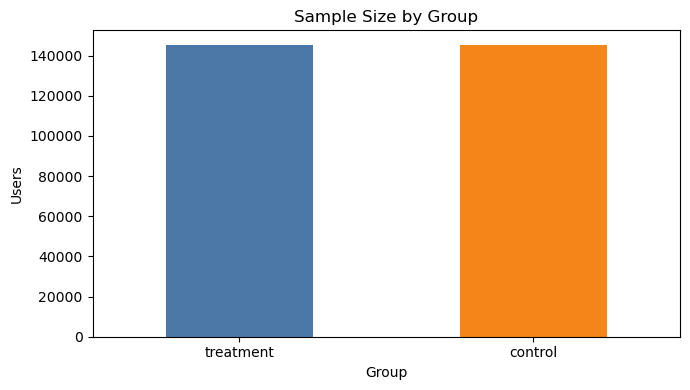

In [39]:
ax = group_summary["sample_size"].plot(kind="bar", color=["#4C78A8", "#F58518"], figsize=(7,4))
ax.set_title("Sample Size by Group")
ax.set_xlabel("Group")
ax.set_ylabel("Users")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


### 19. Graph: Conversion Rate by Group

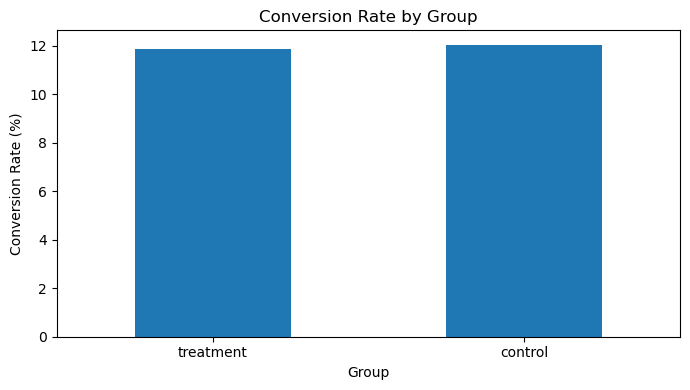

In [40]:
ax = (group_summary["conversion_rate"]*100).plot(kind="bar", figsize=(7,4))
ax.set_title("Conversion Rate by Group")
ax.set_xlabel("Group")
ax.set_ylabel("Conversion Rate (%)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### 20. Graph: Conversion Rate with 95% CI

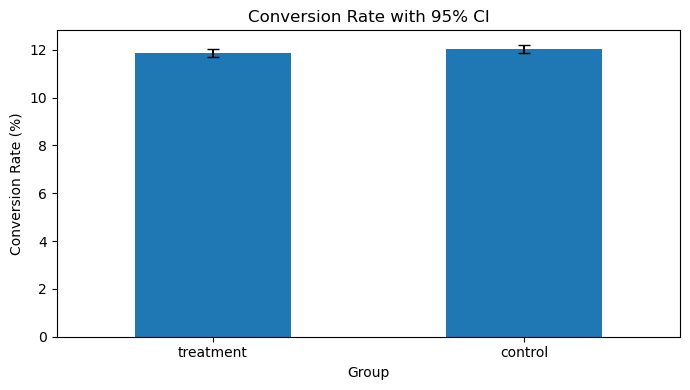

In [42]:
rates = group_summary["conversion_rate"]
sample_sizes = group_summary["sample_size"]
errors = 1.96 * np.sqrt(rates * (1-rates) / sample_sizes)

ax = (rates * 100).plot(kind="bar", yerr = errors * 100, capsize=4, figsize=(7,4))
ax.set_title("Conversion Rate with 95% CI")
ax.set_xlabel("Group")
ax.set_ylabel("Conversion Rate (%)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### 21. Graph: Bootstrap Distribution

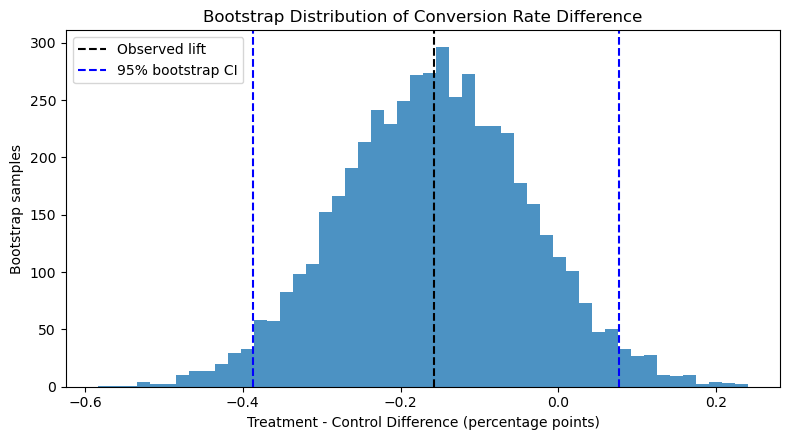

In [44]:
plt.figure(figsize=(8, 4.5))
plt.hist(bootstrap_diffs*100, bins=50, alpha=0.8)
plt.axvline(absolute_lift*100, color="black", linestyle="--", label="Observed lift")
plt.axvline(boot_ci_low*100, color="blue", linestyle="--", label="95% bootstrap CI")
plt.axvline(boot_ci_high*100, color="blue", linestyle="--")
plt.title("Bootstrap Distribution of Conversion Rate Difference")
plt.xlabel("Treatment - Control Difference (percentage points)")
plt.ylabel("Bootstrap samples")
plt.legend()
plt.tight_layout()
plt.show()

### Graph: Conversion Rate by Day

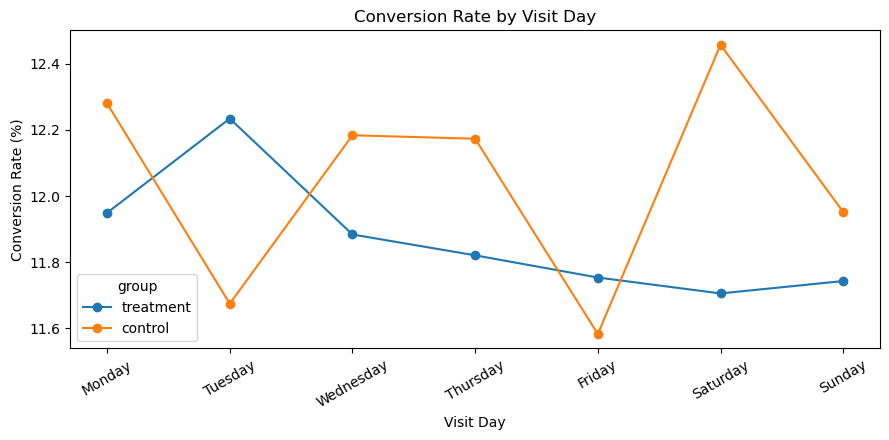

In [47]:
day_plot=day_summary.pivot(index="visit_day", columns="group", values="conversion_rate").reindex(day_order).mul(100)
ax = day_plot[["treatment", "control"]].plot(marker="o", figsize=(9, 4.5))
ax.set_title("Conversion Rate by Visit Day")
ax.set_xlabel("Visit Day")
ax.set_ylabel("Conversion Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Graph: Conversion Rate by Hour

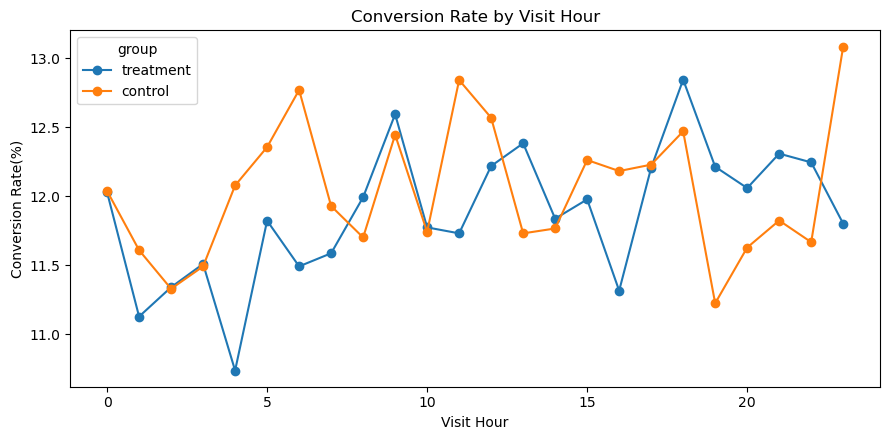

In [48]:
hour_plot = hour_summary.pivot(index="visit_hour", columns="group", values="conversion_rate").mul(100)
ax=hour_plot[["treatment", "control"]].plot(marker="o", figsize=(9, 4.5))
ax.set_title("Conversion Rate by Visit Hour")
ax.set_xlabel("Visit Hour")
ax.set_ylabel("Conversion Rate(%)")
plt.tight_layout()
plt.show()

### 24. Business Conclusion

In [50]:
alpha=0.05
print("Business Conclusion")
print("--------------------")
print(f"Treatment conversion rate: {p_treat:.4%}")
print(f"Control conversion rate: {p_control:.4%}")
print(f"Absolute lift: {absolute_lift:.4%}")
print(f"Relative lift: {relative_lift:.4%}")
print(f"Two-proportion z-test p-value: {z_p_value:.4%}")
print(f"95% CI for difference: [{ci_low:.4%}, {ci_high:.4%}]")
print(f"95% bootstrap CI: [{boot_ci_low:.4%}, {boot_ci_high:.4%}]")

if z_p_value < alpha and absolute_lift > 0 and ci_low > 0 and boot_ci_low > 0: recommendation = "Ship the new landing page." #p<0.05 significant
elif z_p_value < alpha and absolute_lift < 0: recommendation = "Do not ship the new landing page. It performs worse than control." #p<0.05 significant
else: recommendation = "Do not ship yet. The test does not show strong evidence that the new page improves conversion." # not significant
print(f"\nRecommendation: {recommendation}")

Business Conclusion
--------------------
Treatment conversion rate: 11.8808%
Control conversion rate: 12.0386%
Absolute lift: -0.1578%
Relative lift: -1.3110%
Two-proportion z-test p-value: 18.9883%
95% CI for difference: [-0.3938%, 0.0781%]
95% bootstrap CI: [-0.3870%, 0.0769%]

Recommendation: Do not ship yet. The test does not show strong evidence that the new page improves conversion.
